In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="darkgrid")
RANDOM_STATE = 37

In [2]:
diabetes = pd.read_csv("datasets/diabetes.csv")
diabetes.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


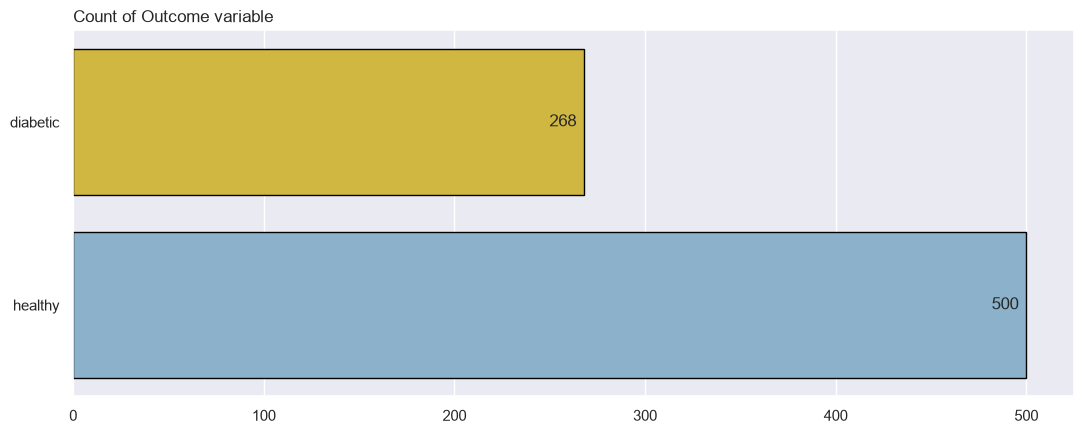

In [3]:
counts = diabetes["Outcome"].map({0: "healthy", 1: "diabetic"}).value_counts().reindex(["diabetic", "healthy"], fill_value=0).rename_axis("Outcome").reset_index(name="Count")
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=counts, x="Count", y="Outcome", hue="Outcome",
    palette={"diabetic": "#E8C629", "healthy": "#80B5D5"},
    dodge=False,
    edgecolor="black",
    legend=False,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        label_type="edge",
        padding=-25
    )

ax.set_title("Count of Outcome variable", loc="left")
ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [4]:
# Pregnancies -> تعداد بارداری‌ها
# Glucose -> قند خون
# BloodPressure -> فشار خون
# SkinThickness -> ضخامت چین پوستی
# Insulin -> انسولین
# BMI -> شاخص توده بدنی
# DiabetesPedigreeFunction -> شاخص سابقه خانوادگی دیابت
# Age -> سن
# Outcome -> نتیجه‌(دیابت دارد یا خیر)

(diabetes == 0).sum()

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [5]:
zero_features = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
impute_stat = {"Glucose": "mean", "BloodPressure": "median", "SkinThickness": "median", "Insulin": "median", "BMI": "median"}
diabetes[zero_features] = diabetes[zero_features].replace(0, np.nan)
for feature, stat in impute_stat.items():
    diabetes[feature] = diabetes.groupby("Outcome")[feature].transform(lambda s, stat=stat: s.fillna(getattr(s, stat)()))

((diabetes == 0) | diabetes.isna()).sum()

Pregnancies                 111
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                       0
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [6]:
# EDA-derived features
def add_extracted_features(df):
    df = df.copy()
    df["HighBP_HighGlucose"] = ((df["BloodPressure"] > 80) & (df["Glucose"] > 105)).astype(int)
    df["HighBP"] = (df["BloodPressure"] > 80).astype(int)
    return df


diabetes = add_extracted_features(diabetes)
diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,HighBP_HighGlucose,HighBP
0,6,148.0,72.0,35.0,169.5,33.6,0.627,50,1,0,0
1,1,85.0,66.0,29.0,102.5,26.6,0.351,31,0,0,0
2,8,183.0,64.0,32.0,169.5,23.3,0.672,32,1,0,0
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0,0,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1,0,0


In [7]:
X = diabetes.copy()
y = X.pop("Outcome")

extended_features = list(X.columns)
normal_features = [f for f in extended_features if f not in ("HighBP_HighGlucose", "HighBP")]
reduced_features = [f for f in normal_features if f not in ("SkinThickness", "DiabetesPedigreeFunction")]

In [8]:
SETUP_TITLES = {
    "extended": "Table 3 — all available features and two new extracted features",
    "normal": "Table 4 — without the two new extracted features",
    "reduced": "Table 5 — without SkinThickness, Pedigree and the two new extracted features",
}
FEATURE_SETS = {
    "extended": extended_features,
    "normal": normal_features,
    "reduced": reduced_features,
}

X_scaled = pd.DataFrame(MinMaxScaler().fit_transform(X), columns=X.columns, index=X.index)


def make_split(features):
    return train_test_split(X_scaled[features], y, test_size=0.3, random_state=RANDOM_STATE)


splits = {setup: make_split(features) for setup, features in FEATURE_SETS.items()}

{setup: (f"train={len(s[0])}", f"test={len(s[1])}") for setup, s in splits.items()}

{'extended': ('train=537', 'test=231'),
 'normal': ('train=537', 'test=231'),
 'reduced': ('train=537', 'test=231')}

In [9]:
def plot_confusion_matrix(y_true, y_pred, title="Confusion Matrix"):
    # Paper layout (Table 2): rows = forecasted, columns = actual, positive class first
    cm = confusion_matrix(y_true, y_pred, labels=[1, 0]).T

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu", xticklabels=["Positive (1)", "Negative (0)"], yticklabels=["Positive (1)", "Negative (0)"], annot_kws={"size": 14})
    plt.xlabel("Actual values")
    plt.ylabel("Forecasted values")
    plt.title(title)
    plt.tight_layout()
    plt.show()


def get_metrics(y_true, y_pred, technique):
    return {
        "Classification Technique": technique,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro"),
        "Recall": recall_score(y_true, y_pred, average="macro"),
        "F1": f1_score(y_true, y_pred, average="macro"),
    }

In [10]:
metrics = {"extended": [], "normal": [], "reduced": []}

def run_model(model, label):
    for setup, (X_train, X_test, y_train, y_test) in splits.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        if setup == "extended":
            plot_confusion_matrix(y_test, y_pred, title=f"Confusion matrix for {label} algorithm")
        metrics[setup].append(get_metrics(y_test, y_pred, label))


--- KNN (k=29) ---


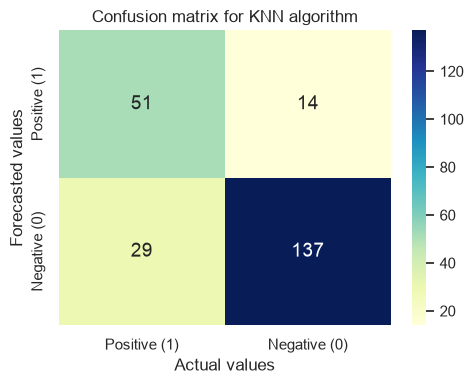

In [11]:
print("\n--- KNN (k=29) ---")
knn = KNeighborsClassifier(n_neighbors=29, weights="distance", metric="minkowski", p=1)
run_model(knn, "KNN")


--- Random forests ---


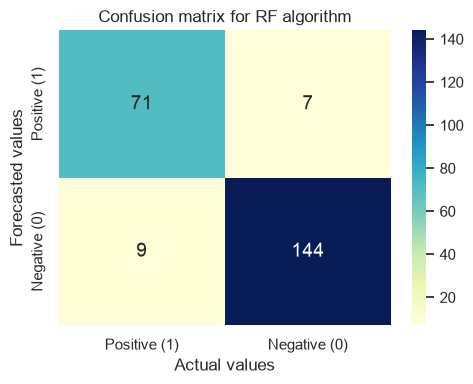

In [12]:
print("\n--- Random forests ---")
rf = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
run_model(rf, "RF")


--- SVM ---


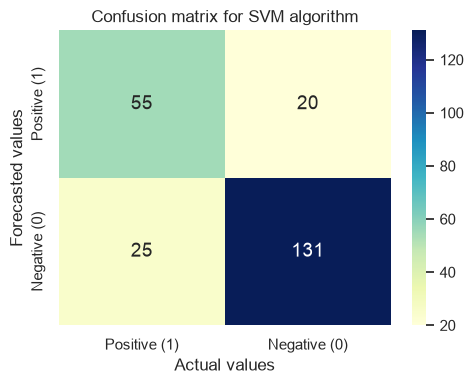

In [13]:
print("\n--- SVM ---")
svm = SVC(kernel="rbf", C=10, gamma="scale", random_state=RANDOM_STATE)
run_model(svm, "SVM")


--- ANN ---


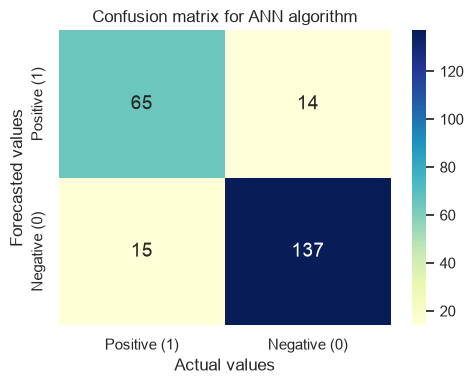

In [14]:
print("\n--- ANN ---")
ann = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    alpha=0.01,
    learning_rate_init=0.001,
    max_iter=2000,
    random_state=RANDOM_STATE,
)
run_model(ann, "ANN")


--- Decision Tree ---


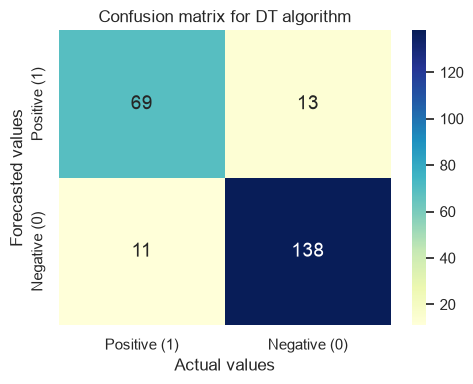

In [15]:
print("\n--- Decision Tree ---")
dt = DecisionTreeClassifier(
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=RANDOM_STATE
)
run_model(dt, "DT")

In [16]:
results = {
    setup: pd.DataFrame(rows).set_index("Classification Technique")
    for setup, rows in metrics.items()
}

for setup, title in SETUP_TITLES.items():
    print(f"—— {title} ——")
    display(results[setup].style.format("{:.2%}"))
    print()

—— Table 3 — all available features and two new extracted features ——


,Accuracy,Precision,Recall,F1
Classification Technique,,,,
KNN,81.39%,80.50%,77.24%,78.39%
RF,93.07%,92.57%,92.06%,92.31%
SVM,80.52%,78.65%,77.75%,78.15%
ANN,87.45%,86.21%,85.99%,86.10%
DT,89.61%,88.38%,88.82%,88.59%



—— Table 4 — without the two new extracted features ——


,Accuracy,Precision,Recall,F1
Classification Technique,,,,
KNN,84.42%,83.36%,81.61%,82.35%
RF,92.21%,91.60%,91.10%,91.34%
SVM,86.58%,85.56%,84.45%,84.95%
ANN,86.58%,85.03%,85.62%,85.31%
DT,88.74%,87.33%,88.16%,87.71%



—— Table 5 — without SkinThickness, Pedigree and the two new extracted features ——


,Accuracy,Precision,Recall,F1
Classification Technique,,,,
KNN,85.71%,84.99%,82.90%,83.77%
RF,92.21%,91.85%,90.81%,91.29%
SVM,86.58%,85.77%,84.15%,84.85%
ANN,90.91%,89.73%,90.40%,90.05%
DT,87.88%,86.39%,87.20%,86.77%


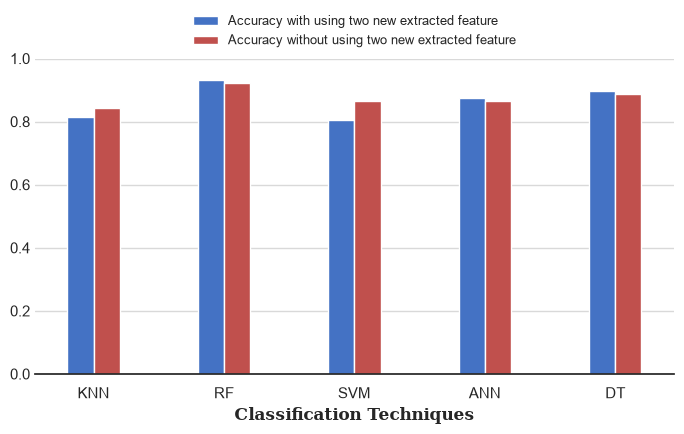

,Accuracy with using two new extracted feature,Accuracy without using two new extracted feature
Classification Technique,,
KNN,81.39%,84.42%
RF,93.07%,92.21%
SVM,80.52%,86.58%
ANN,87.45%,86.58%
DT,89.61%,88.74%


In [17]:
accuracy = pd.DataFrame({
    "Accuracy with using two new extracted feature": results["extended"]["Accuracy"],
    "Accuracy without using two new extracted feature": results["normal"]["Accuracy"],
})

with sns.axes_style("white"):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    accuracy.plot(kind="bar", color=["#4472C4", "#C0504D"], width=0.4, ax=ax)
ax.set_ylim(0, 1)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.yaxis.grid(True, color="#D9D9D9")
ax.set_axisbelow(True)
sns.despine(ax=ax, left=True)
ax.tick_params(axis="y", length=0)
ax.set_xlabel("Classification Techniques", fontfamily="serif", fontweight="bold", fontsize=12)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=1, frameon=False, fontsize=9)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

accuracy.style.format("{:.2%}")